In [219]:
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Setup and Data Acquisition

In [220]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

### Folder Directory

In [221]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("../data")      # raw and clean CSV files go here
FIG_DIR = Path("../figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 33


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## Dataset from Kaggle

In [222]:
# Download (or reuse from the cache) the CSV file
csv_path = kh.dataset_download(
    "harlfoxem/housesalesprediction",
    path="kc_house_data.csv",
)

# Check if the file is zipped
is_zip = zipfile.is_zipfile(csv_path)

# Read CSV
df = pd.read_csv(
    csv_path,
    compression="zip" if is_zip else None
)

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")


Loaded 21,613 rows and 21 columns


## Dataset card

| | |
|---|---|
| **Name** | HHouse Sales in King County, (USA) |
| **Source** | Kaggle, [jharlfoxem/housesalesprediction](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction/data) |
| **Origin** | Information not available |
| **Unit of observation** | One row = One house valuation record |
| **Size (raw)** | 21,613 rows × 21 columns |
| **Target for Day 2** | `price`: price valuation of the house|
| **Licence** | CCO: Public Domain |
| **Known limitations** | |


In [223]:
raw_path = DATA_DIR / "kc_house_data_raw.csv"

# Writing 100+ MB takes a few seconds, so we only do it the first time
if not raw_path.exists():
    df.to_csv(raw_path, index=False)  # index=False: do not write pandas' row numbers as an extra column
    print(f"Raw data saved to {raw_path}")
else:
    print(f"Raw data already saved in {raw_path}")

Raw data already saved in ../data/kc_house_data_raw.csv


## First Look at the Data

In [224]:
df.shape

(21613, 21)

In [225]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


In [226]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

## Initial Data Inspection

The dataset contains 21,613 rows and 21 columns, with no missing values reported in any column.

All columns contain numerical data (int64 or float64), except for date, which is stored as a string and will need to be converted to a datetime format.

However, having no missing values does not necessarily mean the data is clean or ready for analysis. Before proceeding, we need to check whether the values are valid, consistent, and meaningful.

In [227]:
df.describe(include="all")

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,"21,613.00",21613,"21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00"
unique,NaN,372,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,20140623T000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,"4,580,301,520.86",NaN,"540,088.14",3.37,2.11,"2,079.90","15,106.97",1.49,0.01,0.23,3.41,7.66,"1,788.39",291.51,"1,971.01",84.40,"98,077.94",47.56,-122.21,"1,986.55","12,768.46"
std,"2,876,565,571.31",NaN,"367,127.20",0.93,0.77,918.44,"41,420.51",0.54,0.09,0.77,0.65,1.18,828.09,442.58,29.37,401.68,53.51,0.14,0.14,685.39,"27,304.18"
min,"1,000,102.00",NaN,"75,000.00",0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,"1,900.00",0.00,"98,001.00",47.16,-122.52,399.00,651.00
25%,"2,123,049,194.00",NaN,"321,950.00",3.00,1.75,"1,427.00","5,040.00",1.00,0.00,0.00,3.00,7.00,"1,190.00",0.00,"1,951.00",0.00,"98,033.00",47.47,-122.33,"1,490.00","5,100.00"
50%,"3,904,930,410.00",NaN,"450,000.00",3.00,2.25,"1,910.00","7,618.00",1.50,0.00,0.00,3.00,7.00,"1,560.00",0.00,"1,975.00",0.00,"98,065.00",47.57,-122.23,"1,840.00","7,620.00"
75%,"7,308,900,445.00",NaN,"645,000.00",4.00,2.50,"2,550.00","10,688.00",2.00,0.00,0.00,4.00,8.00,"2,210.00",560.00,"1,997.00",0.00,"98,118.00",47.68,-122.12,"2,360.00","10,083.00"


### Data Dictionary


| Column | Meaning | Problem spotted |
|---|---|---|
| `id` | Unique identifier for each house sold | |
| `date` | Date of the house sale | |
| `price` | Sale price of the house | |
| `bedrooms` | Number of bedrooms | |
| `bathrooms` | Number of bathrooms; 0.5 represents a toilet without a shower | |
| `sqft_living` | Interior living area in square feet | |
| `sqft_lot` | Total land area in square feet | |
| `floors` | Number of floors | |
| `waterfront` | Binary indicator of whether the property has a waterfront location | |
| `view` | View quality rating from 0 to 4 | |
| `condition` | Property condition rating from 1 to 5 | |
| `grade` | Construction and design quality rating from 1 to 13 | |
| `sqft_above` | Interior living area above ground level | |
| `sqft_basement` | Interior living area below ground level | |
| `yr_built` | Year the house was originally built | |
| `yr_renovated` | Year of the most recent renovation | |
| `zipcode` | Postal code of the property | |
| `lat` | Latitude of the property | |
| `long` | Longitude of the property | |
| `sqft_living15` | Interior living area of the 15 nearest neighbors | |
| `sqft_lot15` | Lot area of the 15 nearest neighbors | |


# Data Cleaning

We start by creating a copy of the data frame to avoid overwriting the original an to be able to compare before vs after.

In [228]:
df_clean = df.copy()

We reviewed the dataset to identify which aspects of the data require cleaning:

### 1.1 Tidy Columns Names

All column names already follow the snake_case naming convention and are clear and descriptive, so no changes are needed.

### 1.2 Duplicates
We checked the dataset for duplicate records. Since id is a unique identifier assigned to each house rather than a row index, we decided to keep this column instead of dropping it.

In [229]:
# .duplicated() returns True for every row that is an exact copy of an earlier row
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 0


### 1.3 Missing Values Overview
We checked the number of missing values in each column, and the results showed no missing values.



In [230]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
id,0,0.00
grade,0,0.00
sqft_living15,0,0.00
long,0,0.00
lat,0,0.00
zipcode,0,0.00
yr_renovated,0,0.00
yr_built,0,0.00
sqft_basement,0,0.00
sqft_above,0,0.00


We plot the missing values, even though none were found, for the purpose of this exercise.

Figure saved to ../figures/01_missing_values.png


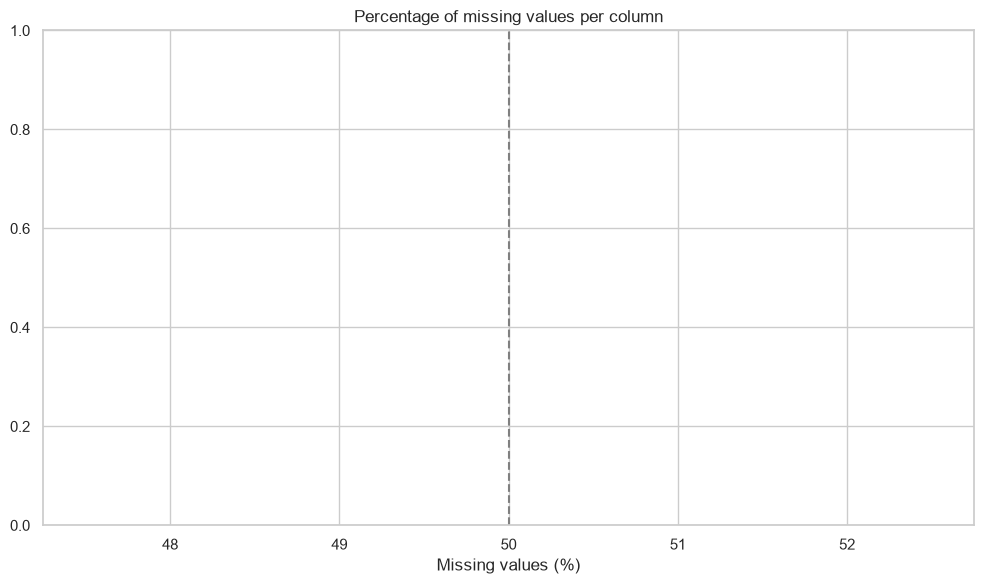

In [231]:
fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

### 1.4 Drop columns we cannot (or will not) use

However, after a closer inspection, we noticed that some columns contain a large number of zeros, particularly waterfront and view.

Since we considered the available information insufficient for imputation, we decided to drop these two columns from the dataset.

In [232]:
columns_to_drop = ["waterfront", "view"]

df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Remaining columns ({df_clean.shape[1]}): {df_clean.columns.tolist()}")

Remaining columns (19): ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


### 1.5 Fix inconsistent data types (text → numbers)

The only column currently stored as a string is date. We convert it to a datetime format so we can properly use this information in our analysis.

In [233]:
df_clean["date"] = pd.to_datetime(df_clean['date'], format='%Y%m%dT%H%M%S')


After the conversion, we check the df info again to confirm that the column now has the correct data type.

In [234]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21613 non-null  int64         
 1   date           21613 non-null  datetime64[us]
 2   price          21613 non-null  float64       
 3   bedrooms       21613 non-null  int64         
 4   bathrooms      21613 non-null  float64       
 5   sqft_living    21613 non-null  int64         
 6   sqft_lot       21613 non-null  int64         
 7   floors         21613 non-null  float64       
 8   condition      21613 non-null  int64         
 9   grade          21613 non-null  int64         
 10  sqft_above     21613 non-null  int64         
 11  sqft_basement  21613 non-null  int64         
 12  yr_built       21613 non-null  int64         
 13  yr_renovated   21613 non-null  int64         
 14  zipcode        21613 non-null  int64         
 15  lat            21613 non-null 

### 1.6 Outliers
We use boxplots to identify potential outliers, errors, or typos in the dataset, focusing on three columns: price, sqft_living, and bedrooms.

Figure saved to ../figures/02_b4Percentile_values.png


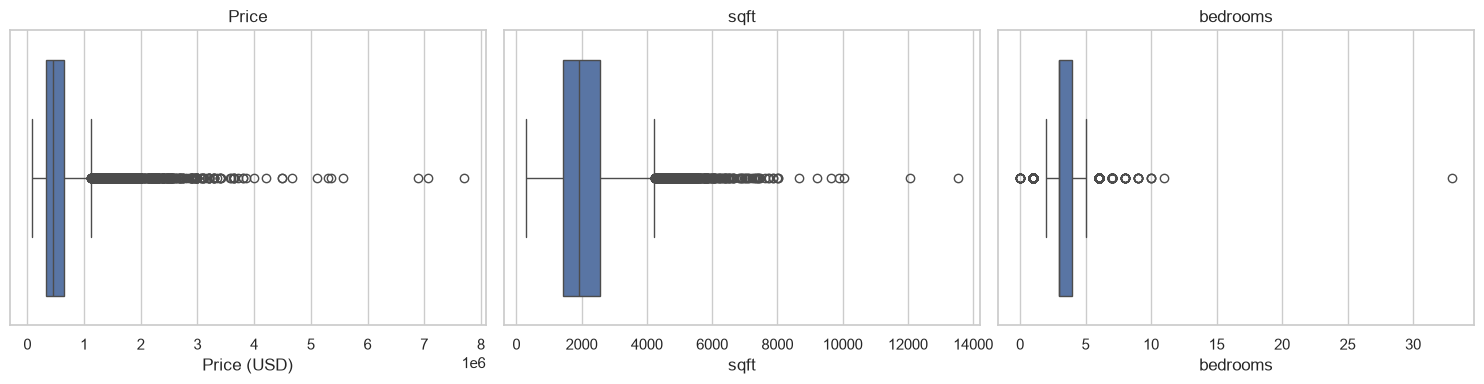

In [235]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(x=df_clean["sqft_living"], ax=axes[1])
axes[1].set_title("sqft")
axes[1].set_xlabel("sqft")

sns.boxplot(x=df_clean["bedrooms"], ax=axes[2])
axes[2].set_title("bedrooms")
axes[2].set_xlabel("bedrooms")

plt.tight_layout()
save_fig("02_b4Percentile_values")
plt.show()

The boxplots show some values that are significantly higher than the rest of the data. The most noticeable outlier is a house listed with 36 bedrooms, which could indicate a data entry error.

We compare the IQR rule and the percentile rule to see how many houses would be removed from the dataset using each method to handle outliers in `price`.

In [236]:
price = df_clean["price"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)

# Percentile rule
p01, p99 = price.quantile([0.01, 0.99])
pct_outliers = (price < p01) | (price > p99)

print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} USD -> removes {iqr_outliers.sum():,} listings")
print(f"Percentile rule: keep {p01:,.1f} to {p99:,.1f} USD -> removes {pct_outliers.sum():,} listings")

IQR rule:        keep -162,625.0 to 1,129,575.0 USD -> removes 1,146 listings
Percentile rule: keep 153,500.4 to 1,964,400.0 USD -> removes 434 listings


We apply the percentile rule to remove outliers from the three main columns: price, sqft_living, and bedrooms.

In [237]:
rows_before = len(df_clean)

# 1) Remove listings without a price (our target variable)
df_clean = df_clean.dropna(subset=["price"])
print(f"Removed {rows_before - len(df_clean):,} listings without a price")


def within_percentiles(series, low=0.01, high=0.99):
    # True for values between the low and high percentiles. Missing values are kept (True):
    # we do not want to delete a row just because one of the columns is unknown.
    lower, upper = series.quantile([low, high])
    return series.isna() | series.between(lower, upper)


# 2) Percentile rule on the three main numeric columns. & means "AND": all three must be OK
keep = (
    within_percentiles(df_clean["price"])
    & within_percentiles(df_clean["sqft_living"])
    & within_percentiles(df_clean["bedrooms"])
)
rows_before_outliers = len(df_clean)
df_clean = df_clean[keep].reset_index(drop=True)
print(f"Removed {rows_before_outliers - len(df_clean):,} outlier listings")
print(f"Rows left: {len(df_clean):,}")

Removed 0 listings without a price
Removed 910 outlier listings
Rows left: 20,703


We generate the boxplots again to visualize how the data distribution changes after removing the outliers.

Figure saved to ../figures/03_new_values.png


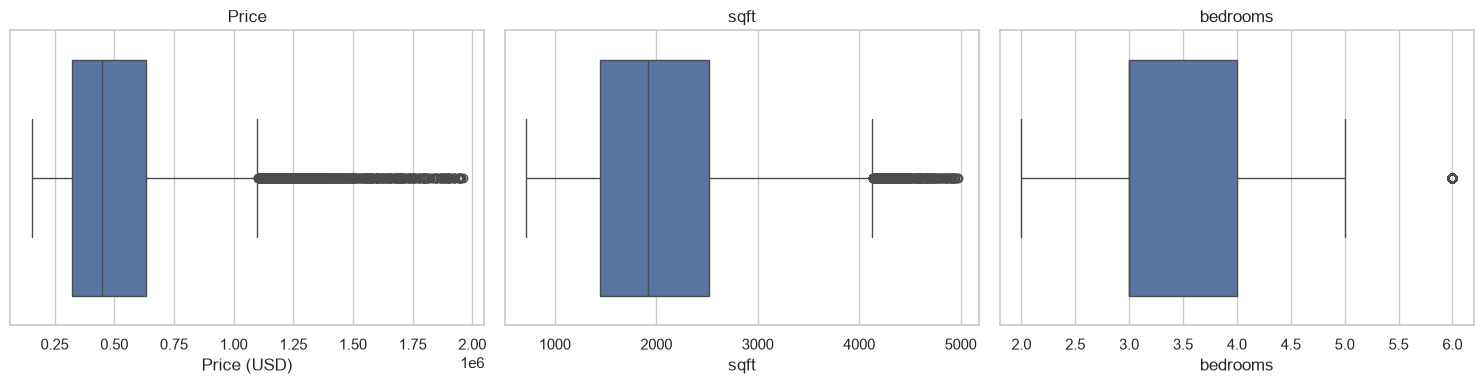

In [238]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(x=df_clean["sqft_living"], ax=axes[1])
axes[1].set_title("sqft")
axes[1].set_xlabel("sqft")

sns.boxplot(x=df_clean["bedrooms"], ax=axes[2])
axes[2].set_title("bedrooms")
axes[2].set_xlabel("bedrooms")

plt.tight_layout()
save_fig("03_new_values")
plt.show()

In [239]:
missing_report(df_clean).head(12)

,n_missing,pct_missing
id,0,0.00
sqft_above,0,0.00
sqft_living15,0,0.00
long,0,0.00
lat,0,0.00
zipcode,0,0.00
yr_renovated,0,0.00
yr_built,0,0.00
sqft_basement,0,0.00
grade,0,0.00


### Final Comparison 
To complete the data cleaning process, we compare the original dataset (df_raw) with the cleaned dataset (df_clean) to review the changes and evaluate the impact of our cleaning steps.

In [240]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,"21,613.00","20,703.00"
columns,21.00,19.00
numeric columns,20.00,18.00
average % missing,0.00,0.00
memory (MB),4.84,3.15


In [241]:
clean_path = DATA_DIR / "kc_houses_data_clean.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Clean data saved to {clean_path} ({clean_path.stat().st_size / 1e6:.1f} MB)")

Clean data saved to ../data/kc_houses_data_clean.csv (2.1 MB)


Finally, we export the cleaned dataset (df_clean) as a CSV file named house_prices_clean.csv, so we can reuse it in future analyses.

Exploratory Data Analysis (EDA)

First we add some columns we need for the analysis: living area in m2, price per sqft, and zipcode as text (we take it as a location, not a number).

In [242]:
SQFT_PER_M2 = 10.7639

df_clean["living_area_m2"] = df_clean["sqft_living"] / SQFT_PER_M2
df_clean["price_per_sqft"] = df_clean["price"] / df_clean["sqft_living"]
df_clean["zipcode"] = df_clean["zipcode"].astype(str)

df_clean[["price", "sqft_living", "living_area_m2", "price_per_sqft", "zipcode"]].head()

,price,sqft_living,living_area_m2,price_per_sqft,zipcode
0,"221,900.00",1180,109.63,188.05,98178
1,"538,000.00",2570,238.76,209.34,98125
2,"180,000.00",770,71.54,233.77,98028
3,"604,000.00",1960,182.09,308.16,98136
4,"510,000.00",1680,156.08,303.57,98074


Descriptive Statistic: 

The mean price (519k USD) is higher than the median (450k USD) because a few very expensive houses pull it up, so we use the median as the typical price. A typical house has 178 m2, 3 bedrooms and was built in 1974.

Bedrooms goes from 0 to 33. 33 is probably a typo (should be 3).

In [243]:
key_numeric = ["price", "price_per_sqft", "living_area_m2", "bedrooms", "bathrooms", "floors", "grade", "yr_built"]

stats = df_clean[key_numeric].describe().T
stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
price,"20,703.00","519,330.89","275,409.69","153,503.00","325,000.00","450,000.00","635,000.00","1,960,000.00",1.72
price_per_sqft,"20,703.00",260.53,103.50,87.71,182.48,243.61,314.66,810.14,1.15
living_area_m2,"20,703.00",190.74,74.30,66.89,134.25,178.37,234.12,461.73,0.80
bedrooms,"20,703.00",3.38,0.84,2.00,3.00,3.00,4.00,6.00,0.42
bathrooms,"20,703.00",2.11,0.72,0.50,1.75,2.25,2.50,5.25,0.20
floors,"20,703.00",1.50,0.54,1.00,1.00,1.50,2.00,3.50,0.61
grade,"20,703.00",7.65,1.09,4.00,7.00,7.00,8.00,13.00,0.73
yr_built,"20,703.00","1,971.49",29.15,"1,900.00","1,952.00","1,976.00","1,997.00","2,015.00",-0.49


Univertiate analysis: numerical variables

How is the price distributed? We plot it in normal scale and log scale because the price is skewed.

Figure saved to ../figures/04_price_distribution.png


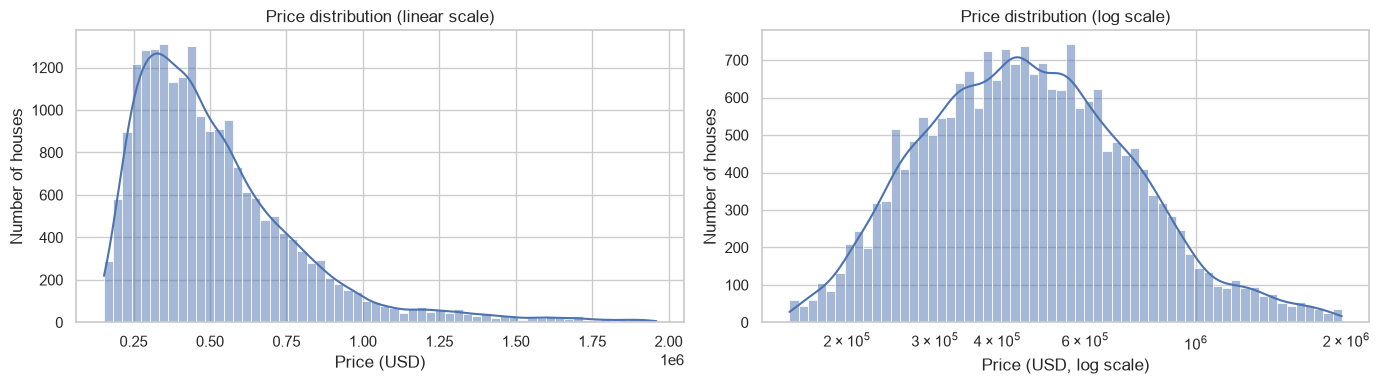

In [244]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_clean["price"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Price distribution (linear scale)")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Number of houses")

sns.histplot(df_clean["price"], bins=60, kde=True, log_scale=True, ax=axes[1])
axes[1].set_title("Price distribution (log scale)")
axes[1].set_xlabel("Price (USD, log scale)")
axes[1].set_ylabel("Number of houses")

plt.tight_layout()
save_fig("04_price_distribution")
plt.show()

In normal scale most houses are on the left. In log scale it looks like a normal (bell) shape, so for Day 2 it makes sense to predict log(price).

How big are the houses and how much is a sqft?

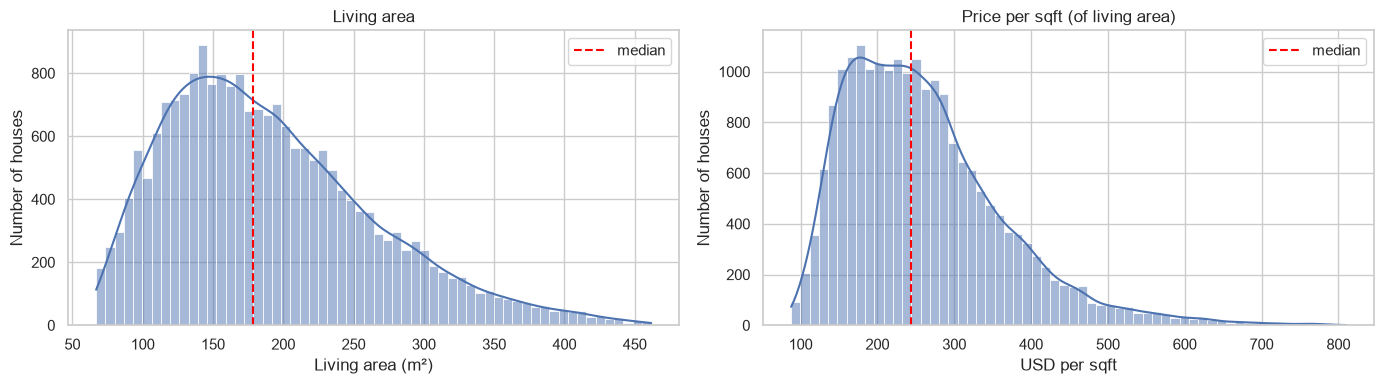

In [245]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_clean["living_area_m2"], bins=60, kde=True, ax=axes[0])
axes[0].axvline(df_clean["living_area_m2"].median(), color="red", linestyle="--", label="median")
axes[0].set_title("Living area")
axes[0].set_xlabel("Living area (m²)")
axes[0].set_ylabel("Number of houses")
axes[0].legend()

sns.histplot(df_clean["price_per_sqft"], bins=60, kde=True, ax=axes[1])
axes[1].axvline(df_clean["price_per_sqft"].median(), color="red", linestyle="--", label="median")
axes[1].set_title("Price per sqft (of living area)")
axes[1].set_xlabel("USD per sqft")
axes[1].set_ylabel("Number of houses")
axes[1].legend()

plt.tight_layout()
plt.show()

Univartiate analysis: categorical variables

What kind of houses are sold? Condition (1-5) and grade (1-13) are ratings given by the county, so we keep them in order.

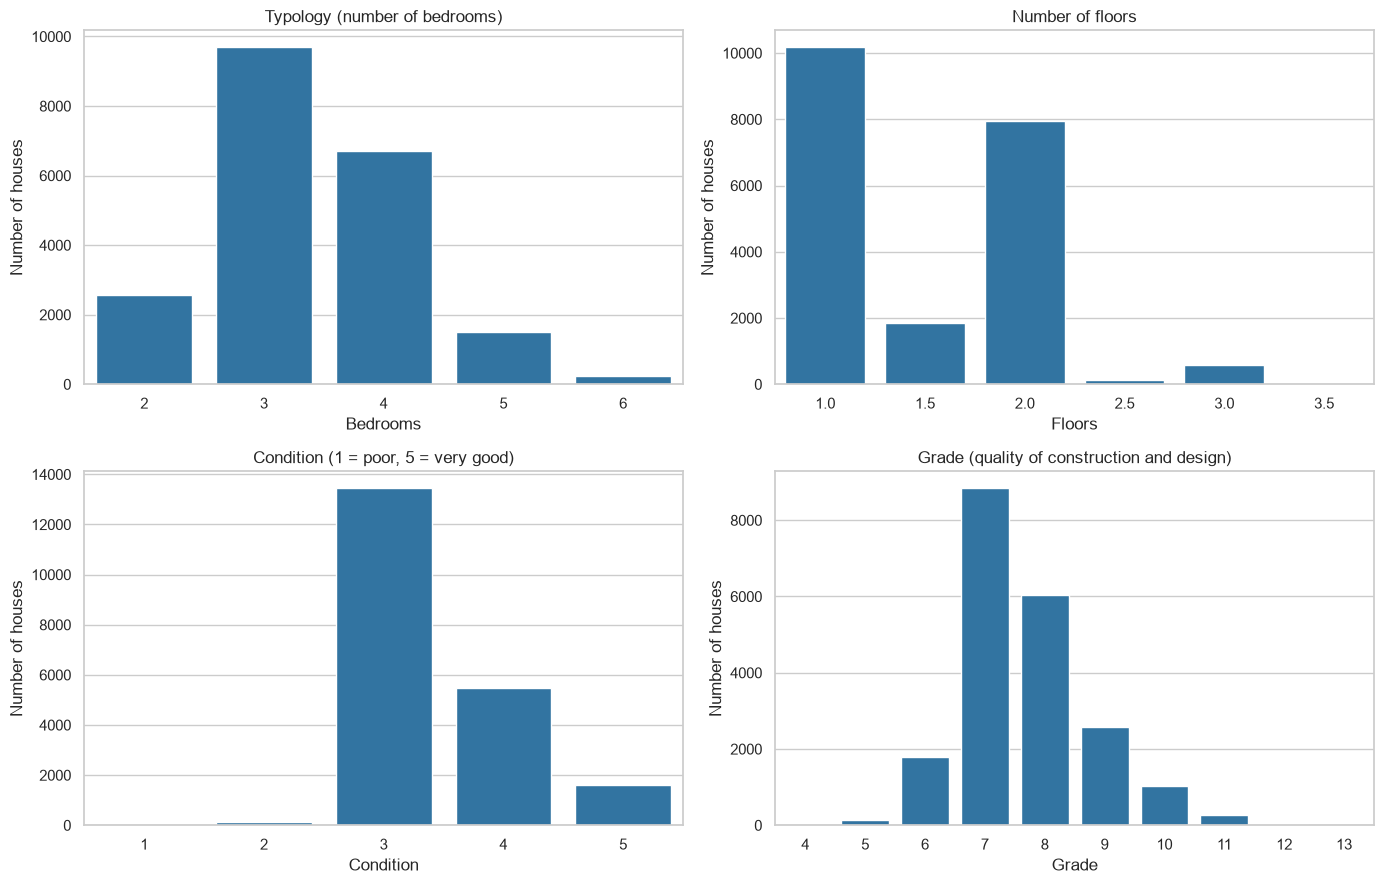

In [246]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(data=df_clean, x="bedrooms", color="tab:blue", ax=axes[0, 0])
axes[0, 0].set_title("Typology (number of bedrooms)")
axes[0, 0].set_xlabel("Bedrooms")

sns.countplot(data=df_clean, x="floors", color="tab:blue", ax=axes[0, 1])
axes[0, 1].set_title("Number of floors")
axes[0, 1].set_xlabel("Floors")

sns.countplot(data=df_clean, x="condition", color="tab:blue", ax=axes[1, 0])
axes[1, 0].set_title("Condition (1 = poor, 5 = very good)")
axes[1, 0].set_xlabel("Condition")

sns.countplot(data=df_clean, x="grade", color="tab:blue", ax=axes[1, 1])
axes[1, 1].set_title("Grade (quality of construction and design)")
axes[1, 1].set_xlabel("Grade")

for ax in axes.flat:
    ax.set_ylabel("Number of houses")

plt.tight_layout()
plt.show()

Most houses have 3 or 4 bedrooms, 1 or 2 floors, condition 3 and grade 7 or 8.

Which zipcodes are in the data?

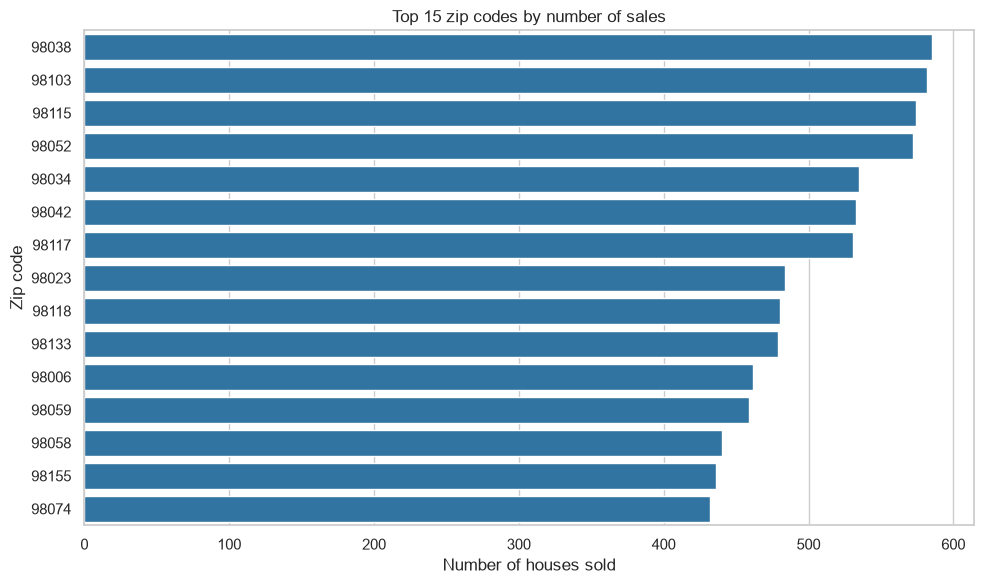

The dataset has 70 zip codes
The top 15 zip codes contain 37% of all houses


In [247]:
top_zipcodes = df_clean["zipcode"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_zipcodes.values, y=top_zipcodes.index, color="tab:blue", ax=ax)
ax.set_title("Top 15 zip codes by number of sales")
ax.set_xlabel("Number of houses sold")
ax.set_ylabel("Zip code")
plt.tight_layout()
plt.show()

print(f"The dataset has {df_clean['zipcode'].nunique()} zip codes")
print(f"The top 15 zip codes contain {top_zipcodes.sum() / len(df_clean):.0%} of all houses")


Bivariate analysis:

Do bigger houses cost more? We use a sample of 5000 houses and log scale on both axes.

Figure saved to ../figures/05_area_vs_price.png


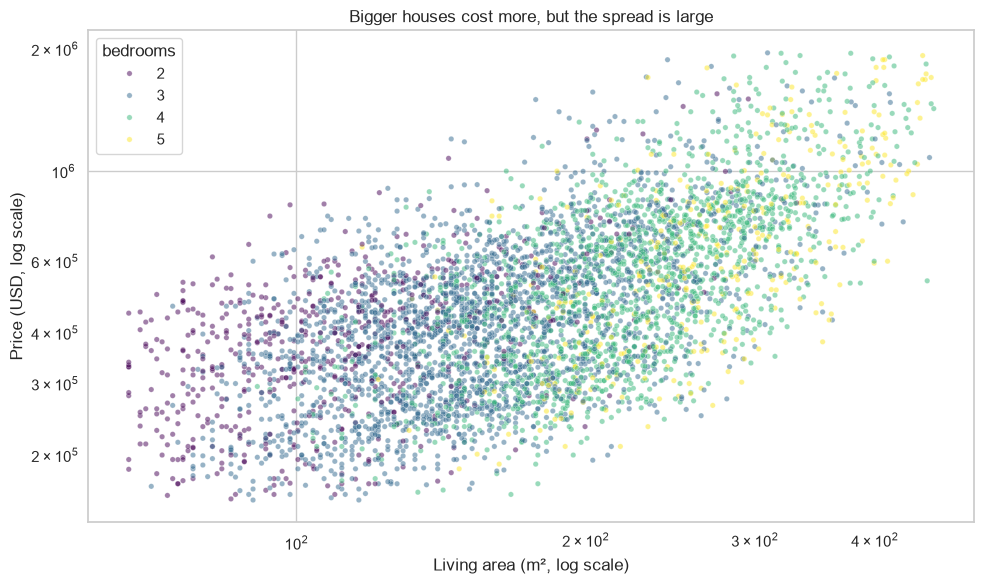

In [248]:
sample = df_clean.sample(5000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample[sample["bedrooms"].between(1, 5)], x="living_area_m2", y="price",
                hue="bedrooms", palette="viridis", alpha=0.5, s=15, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Bigger houses cost more, but the spread is large")
ax.set_xlabel("Living area (m², log scale)")
ax.set_ylabel("Price (USD, log scale)")
plt.tight_layout()
save_fig("05_area_vs_price")
plt.show()

Location is also important.

Figure saved to ../figures/06_price_per_sqft_by_zipcode.png


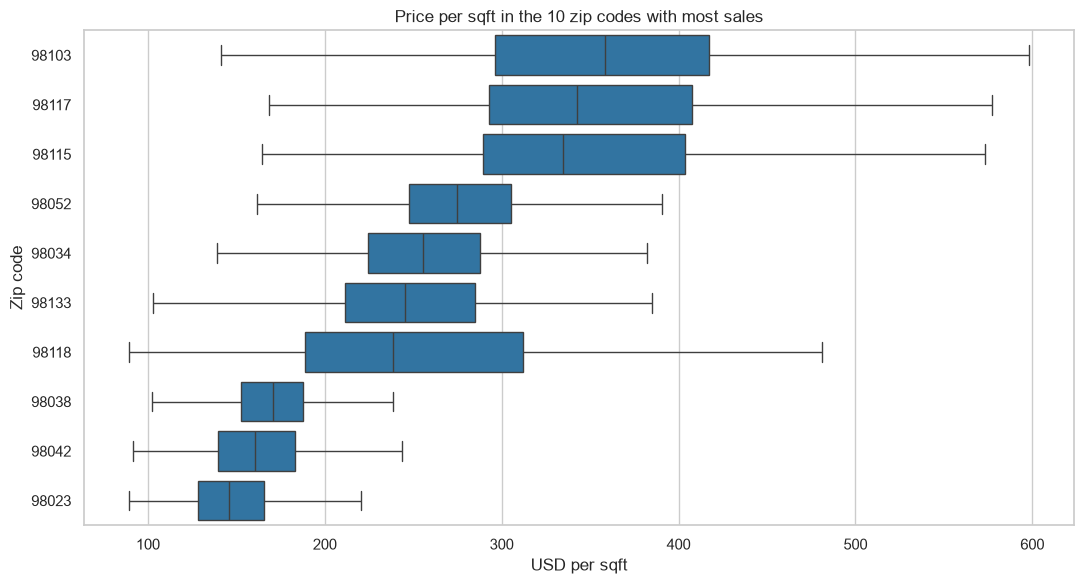

In [249]:
top10_zipcodes = df_clean["zipcode"].value_counts().head(10).index
in_top10 = df_clean[df_clean["zipcode"].isin(top10_zipcodes)]

# order from most to least expensive
zip_order = in_top10.groupby("zipcode")["price_per_sqft"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=in_top10, x="price_per_sqft", y="zipcode", order=zip_order,
            showfliers=False, color="tab:blue", ax=ax)
ax.set_title("Price per sqft in the 10 zip codes with most sales")
ax.set_xlabel("USD per sqft")
ax.set_ylabel("Zip code")
plt.tight_layout()
save_fig("06_price_per_sqft_by_zipcode")
plt.show()

The most expensive zipcode is about 2.5 times more expensive per sqft than the cheapest one.

Some areas are more expensive than others, so we compare each house only with houses in the same zipcode. A value of 1 means a normal price for that area, 1.2 means 20% more expensive and 0.8 means 20% cheaper.

In [250]:
zip_median = df_clean.groupby("zipcode")["price_per_sqft"].transform("median")
df_clean["relative_price"] = df_clean["price_per_sqft"] / zip_median

df_clean["relative_price"].describe()

count   20,703.00
mean         1.04
std          0.26
min          0.27
25%          0.87
50%          1.00
75%          1.15
max          4.06
Name: relative_price, dtype: float64

Does the grade change the value? Median relative price for each grade, the red line is 1 (same as the zipcode median).

Figure saved to ../figures/07_grade_vs_price.png


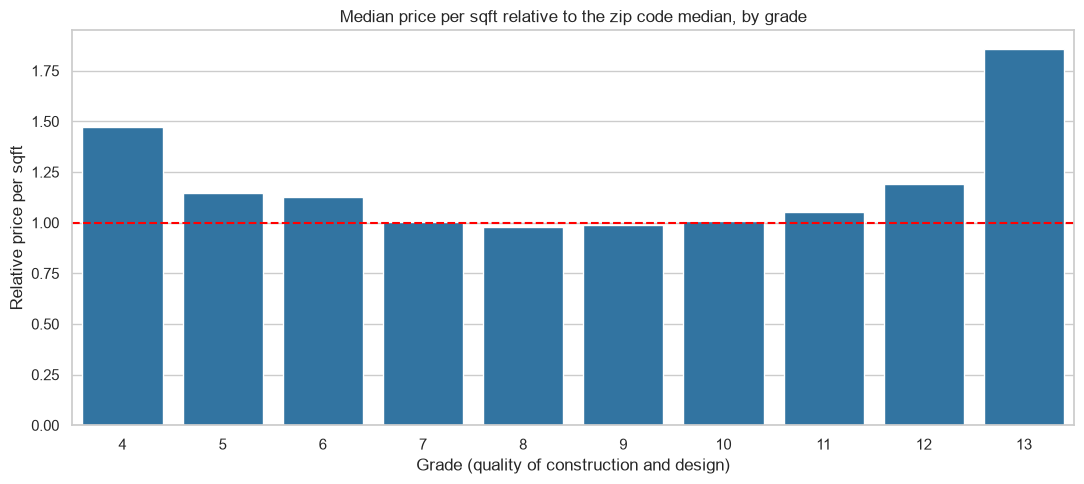

,median,count
grade,,
4,1.47,7
5,1.15,143
6,1.13,1790
7,1.00,8837
8,0.98,6027
9,0.99,2573
10,1.01,1031
11,1.05,260
12,1.19,34


In [251]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=df_clean, x="grade", y="relative_price",
            estimator="median", errorbar=None, color="tab:blue", ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_title("Median price per sqft relative to the zip code median, by grade")
ax.set_xlabel("Grade (quality of construction and design)")
ax.set_ylabel("Relative price per sqft")
plt.tight_layout()
save_fig("07_grade_vs_price")
plt.show()

df_clean.groupby("grade")["relative_price"].agg(["median", "count"])

Grades 7-10 are around 1, but low grades (5-6) and high grades (12-13) are higher. This is probably because of size: low grade houses are small. The total price still goes up with grade. Grade 4 and 13 have very few houses, so we ignore them.


Basement and renovation: we make two True/False columns and use melt to plot them together.

In [252]:
df_clean["has_basement"] = df_clean["sqft_basement"] > 0
df_clean["was_renovated"] = df_clean["yr_renovated"] > 0

features_long = df_clean.melt(
    id_vars="relative_price",
    value_vars=["has_basement", "was_renovated"],
    var_name="feature",
    value_name="has_feature",
)
features_long.head()

,relative_price,feature,has_feature
0,1.06,has_basement,False
1,0.80,has_basement,True
2,1.05,has_basement,False
3,0.98,has_basement,True
4,1.19,has_basement,False


Figure saved to ../figures/08_features_vs_price.png


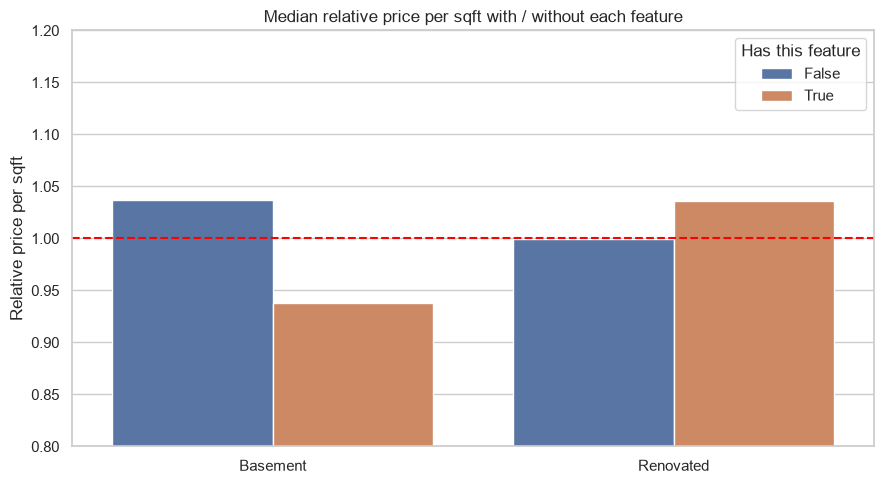

has_basement    0.39
was_renovated   0.04
dtype: float64

In [253]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=features_long, x="feature", y="relative_price", hue="has_feature",
            estimator="median", errorbar=None, ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_ylim(0.8, 1.2)
ax.set_title("Median relative price per sqft with / without each feature")
ax.set_xlabel("")
ax.set_xticks(range(2), ["Basement", "Renovated"])
ax.set_ylabel("Relative price per sqft")
ax.legend(title="Has this feature")
plt.tight_layout()
save_fig("08_features_vs_price")
plt.show()

df_clean[["has_basement", "was_renovated"]].mean()

Houses with a basement are a bit cheaper per sqft than other houses in the same area. These houses are also usually older.

Very few houses are renovated, and they are a bit more expensive than other houses in their area, even though they are old. This does not prove that renovation causes the higher price. 

Next, we check if older or newer houses are more expensive.

Figure saved to ../figures/09_period_vs_price.png


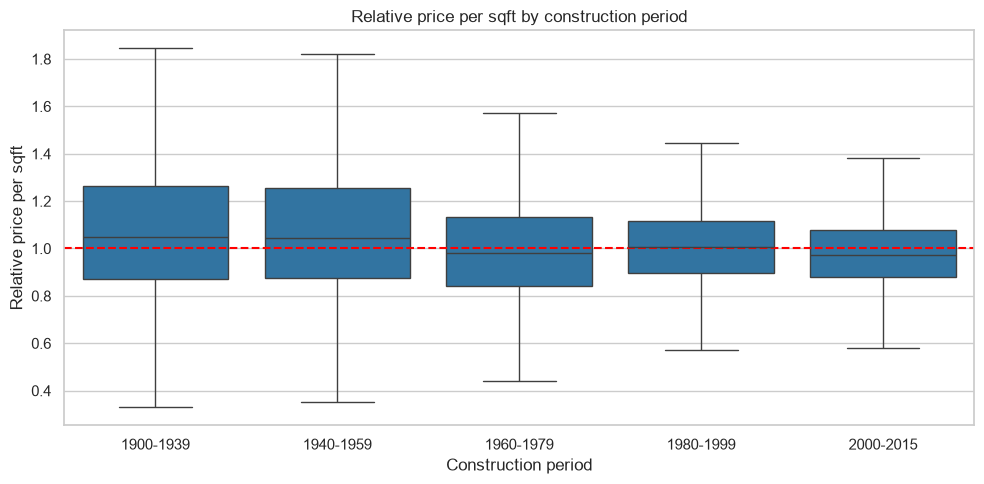

construction_period
1900-1939    2942
1940-1959    3954
1960-1979    4813
1980-1999    4406
2000-2015    4588
Name: count, dtype: int64

In [254]:
df_clean["construction_period"] = pd.cut(
    df_clean["yr_built"],
    bins=[1899, 1939, 1959, 1979, 1999, 2015],
    labels=["1900-1939", "1940-1959", "1960-1979", "1980-1999", "2000-2015"],
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_clean, x="construction_period", y="relative_price", showfliers=False, color="tab:blue", ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_title("Relative price per sqft by construction period")
ax.set_xlabel("Construction period")
ax.set_ylabel("Relative price per sqft")
plt.tight_layout()
save_fig("09_period_vs_price")
plt.show()

df_clean["construction_period"].value_counts().sort_index()

Houses built before 1960 are a bit above their zipcode, newer ones are around 1 or a bit below. Old houses also have the biggest spread. It could be because old houses are smaller, or because of their character or plot, we cannot tell from this data.

Condition and number of floors, side by side with the same y axis.

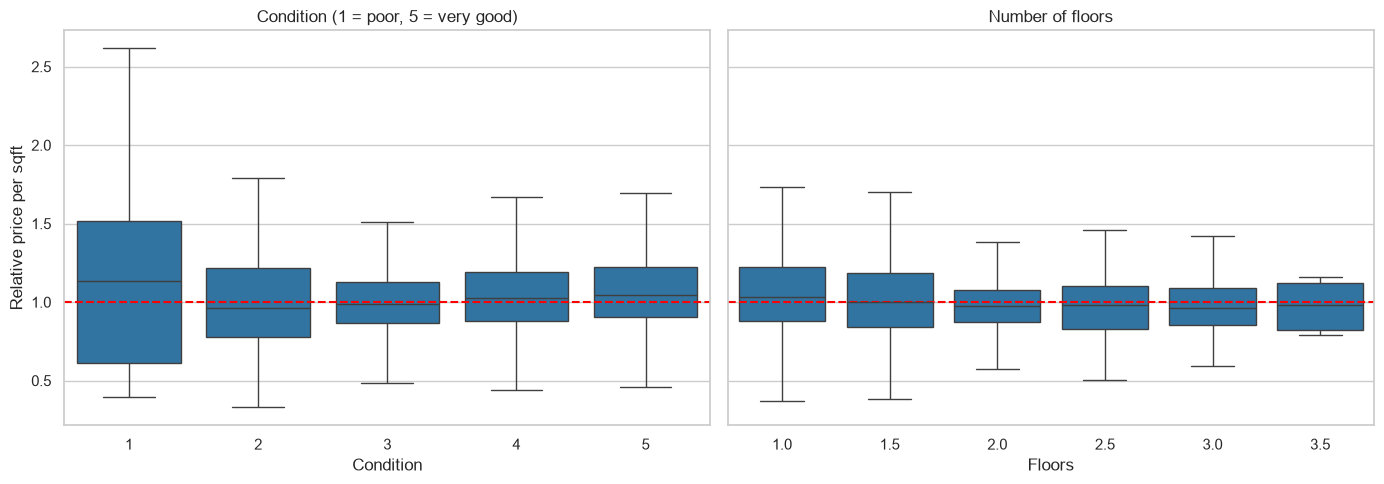

In [255]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.boxplot(data=df_clean, x="condition", y="relative_price", showfliers=False,
            color="tab:blue", ax=axes[0])
axes[0].set_title("Condition (1 = poor, 5 = very good)")
axes[0].set_xlabel("Condition")
axes[0].set_ylabel("Relative price per sqft")

sns.boxplot(data=df_clean, x="floors", y="relative_price", showfliers=False,
            color="tab:blue", ax=axes[1])
axes[1].set_title("Number of floors")
axes[1].set_xlabel("Floors")

for ax in axes:
    ax.axhline(1, color="red", linestyle="--")

plt.tight_layout()
plt.show()

Better condition has a slightly higher relative price. One floor houses are the most expensive per sqft and two floor houses a bit cheaper, again probably because of size.

In general price per sqft is higher for small houses, so for Day 2 it is better to predict the total price (log) and use the area as an input.